In [1]:
import glob
mat_files = sorted(glob.glob("/kaggle/input/**/*.mat", recursive=True))
print(len(mat_files))
print(mat_files[:3])

3064
['/kaggle/input/datasets/hieuvodoanminh/jun-chengs-2017-brain-tumor-dataset/segbraintumors/brainTumorDataPublic_1-766/1.mat', '/kaggle/input/datasets/hieuvodoanminh/jun-chengs-2017-brain-tumor-dataset/segbraintumors/brainTumorDataPublic_1-766/10.mat', '/kaggle/input/datasets/hieuvodoanminh/jun-chengs-2017-brain-tumor-dataset/segbraintumors/brainTumorDataPublic_1-766/100.mat']


shape: (512, 512) dtype: int16 min/max: 0 3366


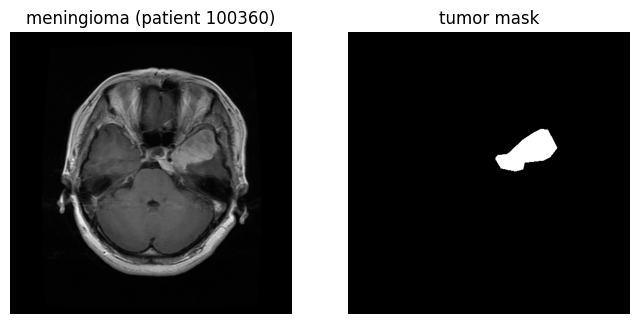

In [2]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

with h5py.File(mat_files[0], "r") as f:
    data = f["cjdata"]
    image = np.array(data["image"]).T
    mask  = np.array(data["tumorMask"]).T
    label = int(np.array(data["label"]).item())
    pid   = "".join(chr(c) for c in np.array(data["PID"]).flatten())

print("shape:", image.shape, "dtype:", image.dtype, "min/max:", image.min(), image.max())

names = {1: "meningioma", 2: "glioma", 3: "pituitary"}
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(image, cmap="gray")
axes[0].set_title(f"{names[label]} (patient {pid})")
axes[1].imshow(mask, cmap="gray")
axes[1].set_title("tumor mask")
for ax in axes:
    ax.axis("off")
plt.show()